# EDA on Original Images

In [31]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image

In [22]:
root_path_test = r"C:\Users\admin\Desktop\data\test"
root_path_train = r"C:\Users\admin\Desktop\data\train"
root_path_valid = r"C:\Users\admin\Desktop\data\valid"

In [ ]:
# Function to collect images and labels from a folder
def collect_images_from_folder(folder_path):
    data = []
    for label in os.listdir(folder_path):
        label_path = os.path.join(folder_path, label)
        if os.path.isdir(label_path):  # Ensure it's a directory
            for img_name in os.listdir(label_path):
                if img_name.endswith(('.png', '.jpg', '.jpeg')):  # Check for valid image files
                    img_path = os.path.join(label_path, img_name)
                    img_path = img_path.replace('\\', '/')  # Standardize path slashes
                    data.append((img_path, label))  # Append image path and label as a tuple
    return pd.DataFrame(data, columns=['image_path', 'label'])  # Return as a DataFrame

In [19]:
# Create DataFrames for train, valid, and test
og_train_df = collect_images_from_folder(root_path_train)
og_valid_df = collect_images_from_folder(root_path_valid)
og_test_df = collect_images_from_folder(root_path_test)

In [20]:
# Create a master DataFrame with all images (train + valid + test)
og_data_df = pd.concat([og_train_df, og_valid_df, og_test_df], ignore_index=True)

In [21]:
# Display the shape of each DataFrame to verify the data
print("Training set shape:", og_train_df.shape)
print("Validation set shape:", og_valid_df.shape)
print("Test set shape:", og_test_df.shape)
print("Total dataset shape:", og_data_df.shape)

Training set shape: (128, 2)
Validation set shape: (26, 2)
Test set shape: (26, 2)
Total dataset shape: (180, 2)


In [23]:
# Display the first few rows of each DataFrame
print("Training DataFrame sample:\n", og_train_df.head())
print("Validation DataFrame sample:\n", og_valid_df.head())
print("All Data DataFrame sample:\n", og_data_df.head())

Training DataFrame sample:
                                           image_path   label
0  C:/Users/admin/Desktop/data/train/Aphids/00_ap...  Aphids
1  C:/Users/admin/Desktop/data/train/Aphids/01_ap...  Aphids
2  C:/Users/admin/Desktop/data/train/Aphids/02_ap...  Aphids
3  C:/Users/admin/Desktop/data/train/Aphids/03_ap...  Aphids
4  C:/Users/admin/Desktop/data/train/Aphids/04_ap...  Aphids
Validation DataFrame sample:
                                           image_path        label
0  C:/Users/admin/Desktop/data/valid/Aphids/00_ap...       Aphids
1  C:/Users/admin/Desktop/data/valid/Aphids/01_ap...       Aphids
2  C:/Users/admin/Desktop/data/valid/Botrytis/00_...     Botrytis
3  C:/Users/admin/Desktop/data/valid/Botrytis/01_...     Botrytis
4  C:/Users/admin/Desktop/data/valid/Dehydration/...  Dehydration
All Data DataFrame sample:
                                           image_path   label
0  C:/Users/admin/Desktop/data/train/Aphids/00_ap...  Aphids
1  C:/Users/admin/Desktop/data

In [24]:
class_distribution1 = og_data_df['label'].value_counts()
print(class_distribution1)

label
Aphids                   14
Botrytis                 14
Healthy                  14
Leaf Miners              14
Nitrogen Deficiency      14
Nutrient Burn            14
PH Fluctuation           14
Phosphorus Deficiency    14
Potassium Deficiency     14
Powdery Mildew           14
Septoria                 14
Dehydration              13
Overwatering             13
Name: count, dtype: int64


In [25]:
og_train_df['label'].value_counts()

label
Aphids                   10
Botrytis                 10
Healthy                  10
Leaf Miners              10
Nitrogen Deficiency      10
Nutrient Burn            10
PH Fluctuation           10
Phosphorus Deficiency    10
Potassium Deficiency     10
Powdery Mildew           10
Septoria                 10
Dehydration               9
Overwatering              9
Name: count, dtype: int64

In [26]:
og_valid_df['label'].value_counts()

label
Aphids                   2
Botrytis                 2
Dehydration              2
Healthy                  2
Leaf Miners              2
Nitrogen Deficiency      2
Nutrient Burn            2
Overwatering             2
PH Fluctuation           2
Phosphorus Deficiency    2
Potassium Deficiency     2
Powdery Mildew           2
Septoria                 2
Name: count, dtype: int64

In [27]:
def plot_images_label_original1(df):
    unique_labels = og_train_df['label'].unique()
    num_labels = len(unique_labels)

    # Set up the plot (based on the number of unique labels)
    fig, axes = plt.subplots(3, 5, figsize=(15, 9)) # 5 columns and 3 rows
    axes = axes.ravel()

    for idx, label in enumerate(unique_labels):
        # Filter dataframe for the specific label and pick one image
        label_df = og_train_df[(og_train_df['label'] == label)].sample(1)
        img_path = label_df['image_path'].values[0]

        # Read and display the image
        img = Image.open(img_path)
        axes[idx].imshow(img)
        axes[idx].set_title(label)
        axes[idx].axis('off')

    # Turn off any remaining empty axes
    for ax in axes[num_labels:]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

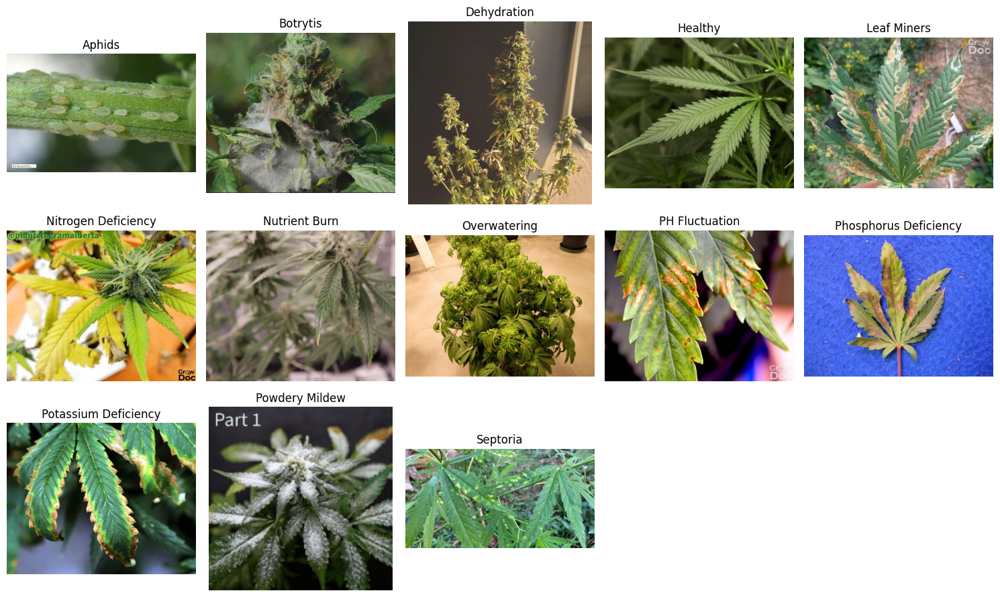

In [28]:
plot_images_label_original1(og_train_df)

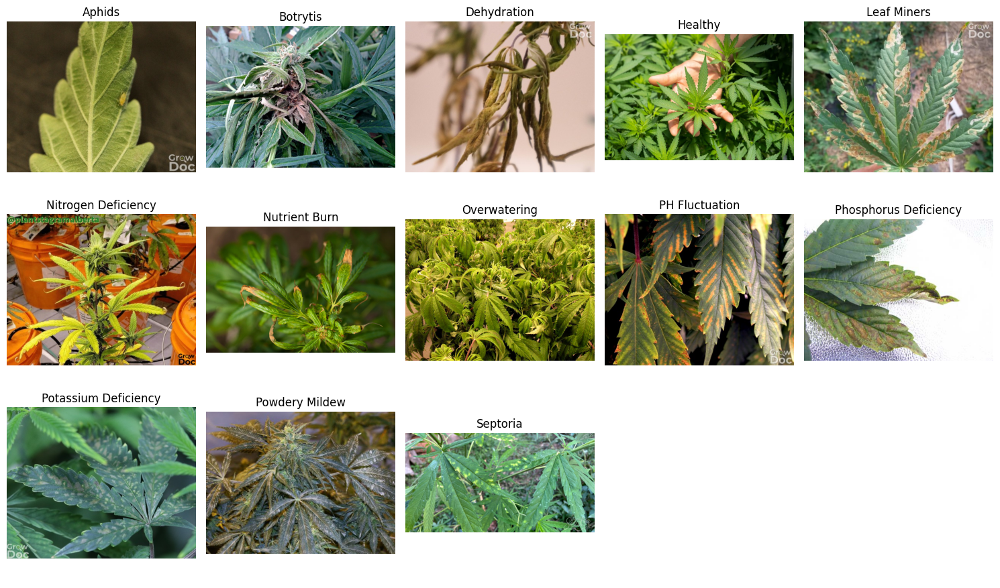

In [29]:
plot_images_label_original1(og_data_df)

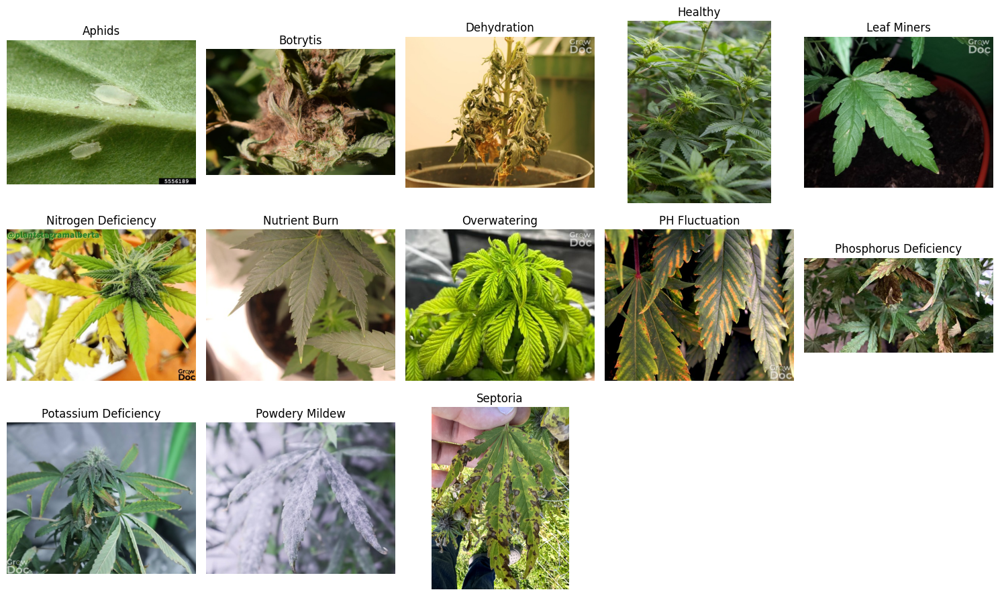

In [30]:
plot_images_label_original1(og_valid_df)

In [5]:
root_path1 = r"C:\Users\admin\Desktop\data\train"

# Initialize empty lists to store the information
sizes1 = []
resolutions1 = []
color_distributions1 = []

# Iterate over each image file in each subdirectory
for dirpath, dirnames, filenames in os.walk(root_path1):
    for filename in filenames:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Load the image file using OpenCV
            img_path = os.path.join(dirpath, filename)
            img = cv2.imread(img_path)

            # Extract the size of the image
            size = os.path.getsize(img_path)
            sizes1.append(size)

            # Extract the resolution of the image
            resolution = img.shape[:2]
            resolutions1.append(resolution)

            # Extract the color distribution of the image
            color_distribution = np.bincount(img.flatten(), minlength=256)
            color_distributions1.append(color_distribution)


In [6]:
# Convert the lists to numpy arrays for easier manipulation
sizes1 = np.array(sizes1)
resolutions1 = np.array(resolutions1)
color_distributions1 = np.array(color_distributions1)

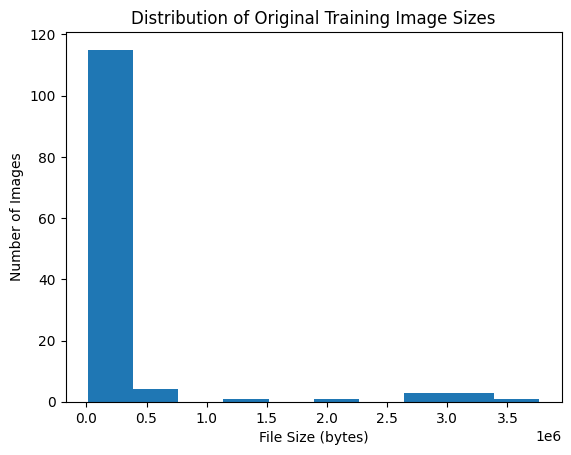

In [7]:
# Plot a histogram of the image sizes
plt.hist(sizes1)
plt.title("Distribution of Original Training Image Sizes")
plt.xlabel("File Size (bytes)")
plt.ylabel("Number of Images")
plt.show()

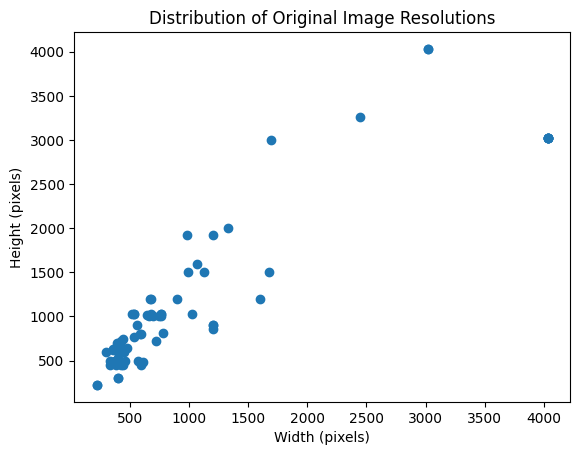

In [9]:
# Plot a scatter plot of the image resolutions
plt.scatter(resolutions1[:, 0], resolutions1[:, 1])
plt.title("Distribution of Original Image Resolutions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.show()

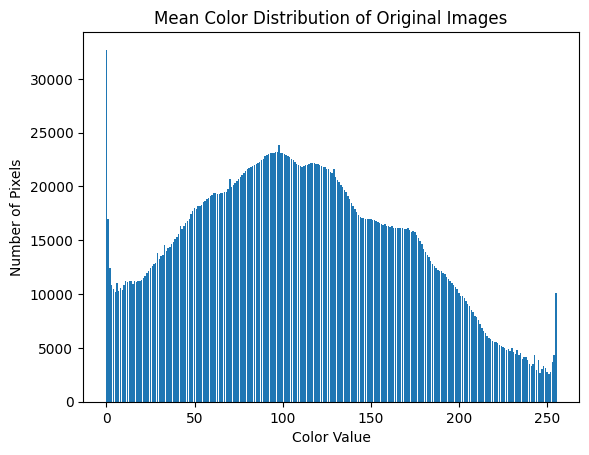

In [10]:
# Calculate the mean color distribution across all images
mean_color_distribution1 = np.mean(color_distributions1, axis=0)

# Plot a bar chart of the mean color distribution
plt.bar(np.arange(256), mean_color_distribution1)
plt.title("Mean Color Distribution of Original Images")
plt.xlabel("Color Value")
plt.ylabel("Number of Pixels")
plt.show()

# EDA on Resized and Augmented Images

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image

In [12]:
# Define paths to the folders
train_dir = '../data/train'
test_dir = '../data/test'
valid_dir = '../data/valid'

In [3]:
data_folder = '../data'

In [13]:
# Function to collect images and labels from a folder
def collect_images_from_folder(folder_path):
    data = []
    for label in os.listdir(folder_path):
        label_path = os.path.join(folder_path, label)
        if os.path.isdir(label_path):  # Ensure it's a directory
            for img_name in os.listdir(label_path):
                if img_name.endswith(('.png', '.jpg', '.jpeg')):  # Check for valid image files
                    img_path = os.path.join(label_path, img_name)
                    img_path = img_path.replace('\\', '/')  # Standardize path slashes
                    data.append((img_path, label))  # Append image path and label as a tuple
    return pd.DataFrame(data, columns=['image_path', 'label'])  # Return as a DataFrame

In [14]:
# Create DataFrames for train, valid, and test
train_df = collect_images_from_folder(train_dir)
valid_df = collect_images_from_folder(valid_dir)
test_df = collect_images_from_folder(test_dir)

In [6]:
# Create a master DataFrame with all images (train + valid + test)
all_data_df = pd.concat([train_df, valid_df, test_df], ignore_index=True)

In [7]:
# Display the shape of each DataFrame to verify the data
print("Training set shape:", train_df.shape)
print("Validation set shape:", valid_df.shape)
print("Test set shape:", test_df.shape)
print("Total dataset shape:", all_data_df.shape)

Training set shape: (1300, 2)
Validation set shape: (260, 2)
Test set shape: (26, 2)
Total dataset shape: (1586, 2)


In [8]:
# Display the first few rows of each DataFrame
print("Training DataFrame sample:\n", train_df.head())
print("Validation DataFrame sample:\n", valid_df.head())
print("All Data DataFrame sample:\n", all_data_df.head())

Training DataFrame sample:
                                        image_path   label
0        ../data/train/Aphids/00_aphids_train.jpg  Aphids
1   ../data/train/Aphids/00_aphids_train_aug0.jpg  Aphids
2  ../data/train/Aphids/00_aphids_train_aug10.jpg  Aphids
3  ../data/train/Aphids/00_aphids_train_aug20.jpg  Aphids
4  ../data/train/Aphids/00_aphids_train_aug30.jpg  Aphids
Validation DataFrame sample:
                                        image_path   label
0        ../data/valid/Aphids/00_aphids_valid.jpg  Aphids
1   ../data/valid/Aphids/00_aphids_valid_aug0.jpg  Aphids
2  ../data/valid/Aphids/00_aphids_valid_aug10.jpg  Aphids
3  ../data/valid/Aphids/00_aphids_valid_aug12.jpg  Aphids
4  ../data/valid/Aphids/00_aphids_valid_aug14.jpg  Aphids
All Data DataFrame sample:
                                        image_path   label
0        ../data/train/Aphids/00_aphids_train.jpg  Aphids
1   ../data/train/Aphids/00_aphids_train_aug0.jpg  Aphids
2  ../data/train/Aphids/00_aphids_train_aug1

In [9]:
class_distribution = all_data_df['label'].value_counts()
print(class_distribution)

label
Aphids                   122
Botrytis                 122
Dehydration              122
Healthy                  122
Leaf Miners              122
Nitrogen Deficiency      122
Nutrient Burn            122
Overwatering             122
PH Fluctuation           122
Phosphorus Deficiency    122
Potassium Deficiency     122
Powdery Mildew           122
Septoria                 122
Name: count, dtype: int64


In [10]:
train_df['label'].value_counts()

label
Aphids                   100
Botrytis                 100
Dehydration              100
Healthy                  100
Leaf Miners              100
Nitrogen Deficiency      100
Nutrient Burn            100
Overwatering             100
PH Fluctuation           100
Phosphorus Deficiency    100
Potassium Deficiency     100
Powdery Mildew           100
Septoria                 100
Name: count, dtype: int64

In [11]:
valid_df['label'].value_counts()

label
Aphids                   20
Botrytis                 20
Dehydration              20
Healthy                  20
Leaf Miners              20
Nitrogen Deficiency      20
Nutrient Burn            20
Overwatering             20
PH Fluctuation           20
Phosphorus Deficiency    20
Potassium Deficiency     20
Powdery Mildew           20
Septoria                 20
Name: count, dtype: int64

In [18]:
def plot_images_label_original(df):
    unique_labels = train_df['label'].unique()
    num_labels = len(unique_labels)

    # Set up the plot (based on the number of unique labels)
    fig, axes = plt.subplots(3, 5, figsize=(15, 9)) # 5 columns and 3 rows
    axes = axes.ravel()

    for idx, label in enumerate(unique_labels):
        # Filter dataframe for the specific label and pick one image
        label_df = train_df[(train_df['label'] == label) & (~train_df['image_path'].str.contains('_aug'))].sample(1)
        img_path = label_df['image_path'].values[0]

        # Read and display the image
        img = Image.open(img_path)
        axes[idx].imshow(img)
        axes[idx].set_title(label)
        axes[idx].axis('off')

    # Turn off any remaining empty axes
    for ax in axes[num_labels:]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


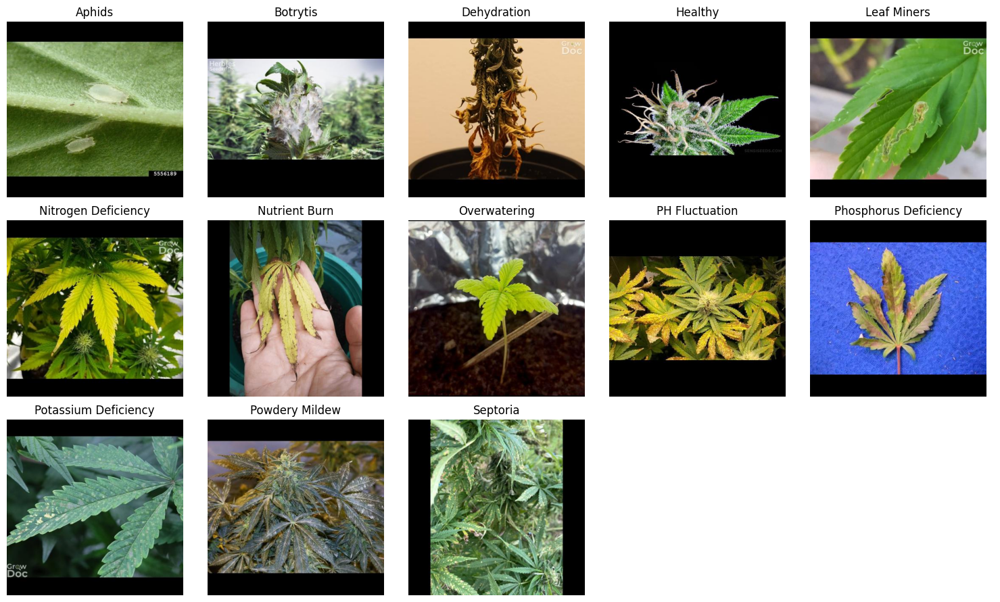

In [19]:
plot_images_label_original(train_df)

In [26]:
def plot_original_and_all_augmented_images(df, label_name, num_augmented=9):
    # Filter dataframe for the specific label (e.g., "Septoria")
    label_df = train_df[train_df['label'] == label_name]

    # Select one original image (without '_aug')
    original_df = label_df[~label_df['image_path'].str.contains('_aug')].sample(1)
    original_img_path = original_df['image_path'].values[0]

    # Select augmented images (with '_aug'), limit to 'num_augmented'
    augmented_df = label_df[label_df['image_path'].str.contains('_aug')].sample(n=num_augmented)
    augmented_img_paths = augmented_df['image_path'].values

    # Set up the plot (2x5 grid to show 1 original and 9 augmented images)
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.ravel()

    # Plot the original image
    original_img = Image.open(original_img_path)
    axes[0].imshow(original_img)
    axes[0].set_title(f'Original: {label_name}')
    axes[0].axis('off')

    # Plot the augmented images
    for idx, aug_img_path in enumerate(augmented_img_paths):
        aug_img = Image.open(aug_img_path)
        axes[idx + 1].imshow(aug_img)
        axes[idx + 1].set_title(f'Augmented {idx + 1}')
        axes[idx + 1].axis('off')

    # Turn off any remaining empty axes (if fewer than 10 images)
    for ax in axes[len(augmented_img_paths) + 1:]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


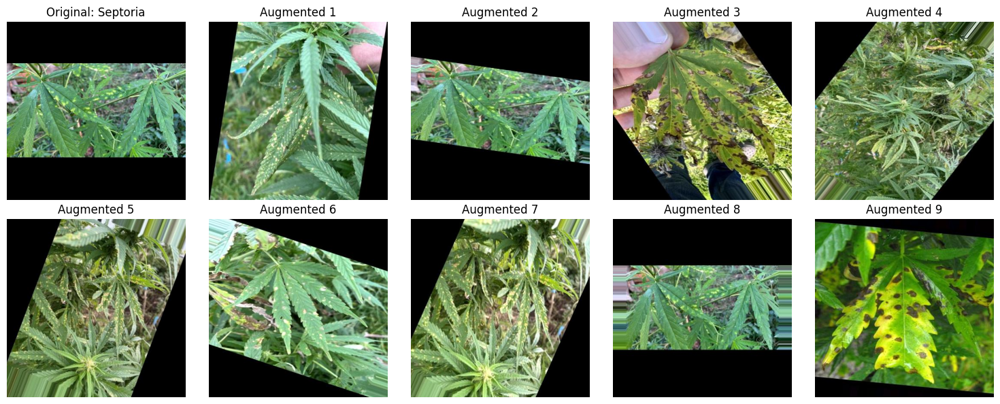

In [27]:
plot_original_and_all_augmented_images(train_df, label_name='Septoria', num_augmented=9)

In [28]:
def plot_first_ten_images(df, label_name):
    # Filter dataframe for the specific label (e.g., "Septoria")
    label_df = train_df[train_df['label'] == label_name]

    # Select the first 10 images (both original and augmented)
    selected_images = label_df.head(10)['image_path'].values

    # Set up the plot (2x5 grid to show 10 images)
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.ravel()

    # Plot the selected images
    for idx, img_path in enumerate(selected_images):
        img = Image.open(img_path)
        axes[idx].imshow(img)
        axes[idx].set_title(f'{label_name} {idx + 1}')
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

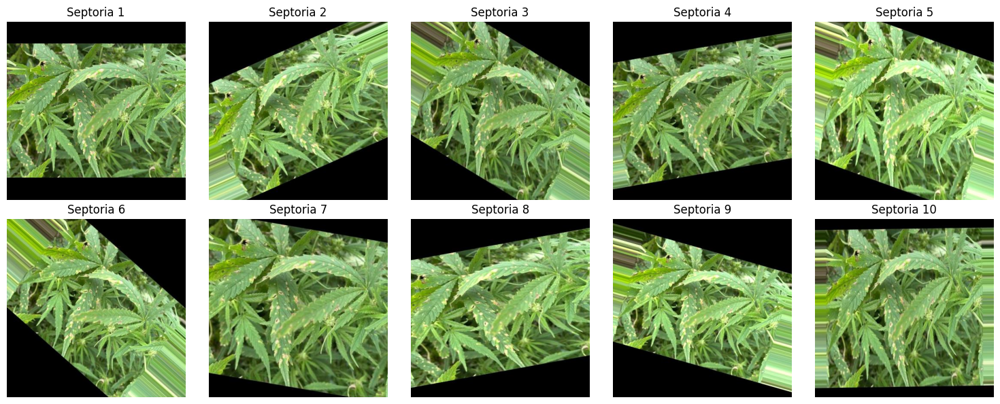

In [29]:
plot_first_ten_images(train_df, label_name='Septoria')

In [33]:
root_path = r"C:\Users\admin\dataScienceBootcamp\cannabis-health-diagnosis\data\train"

# Initialize empty lists to store the information
sizes = []
resolutions = []
color_distributions = []

# Iterate over each image file in each subdirectory
for dirpath, dirnames, filenames in os.walk(root_path):
    for filename in filenames:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Load the image file using OpenCV
            img_path = os.path.join(dirpath, filename)
            img = cv2.imread(img_path)

            # Extract the size of the image
            size = os.path.getsize(img_path)
            sizes.append(size)

            # Extract the resolution of the image
            resolution = img.shape[:2]
            resolutions.append(resolution)

            # Extract the color distribution of the image
            color_distribution = np.bincount(img.flatten(), minlength=256)
            color_distributions.append(color_distribution)


In [34]:
# Convert the lists to numpy arrays for easier manipulation
sizes = np.array(sizes)
resolutions = np.array(resolutions)
color_distributions = np.array(color_distributions)

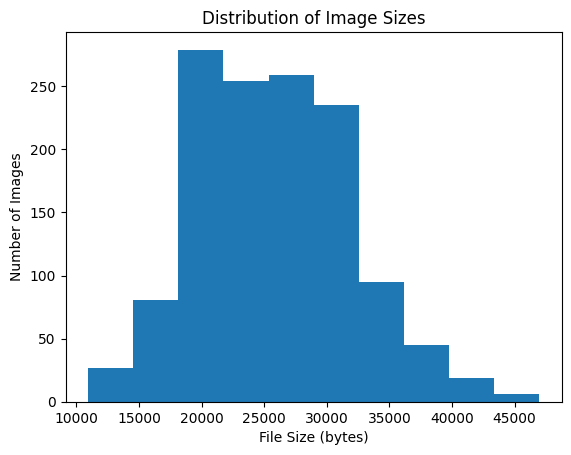

In [35]:
# Plot a histogram of the image sizes
plt.hist(sizes)
plt.title("Distribution of Image Sizes")
plt.xlabel("File Size (bytes)")
plt.ylabel("Number of Images")
plt.show()

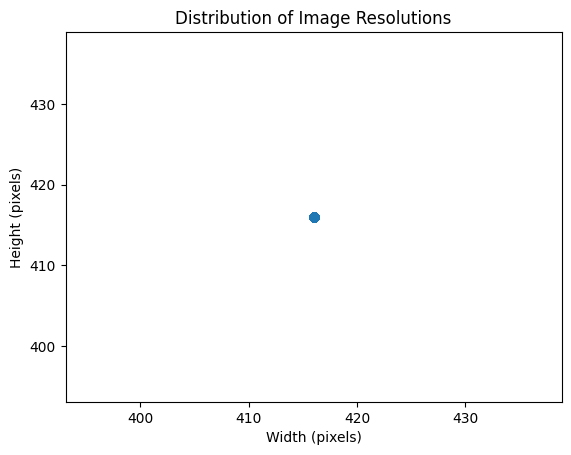

In [44]:
# Plot a scatter plot of the image resolutions
plt.scatter(resolutions[:, 0], resolutions[:, 1])
plt.title("Distribution of Image Resolutions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.show()

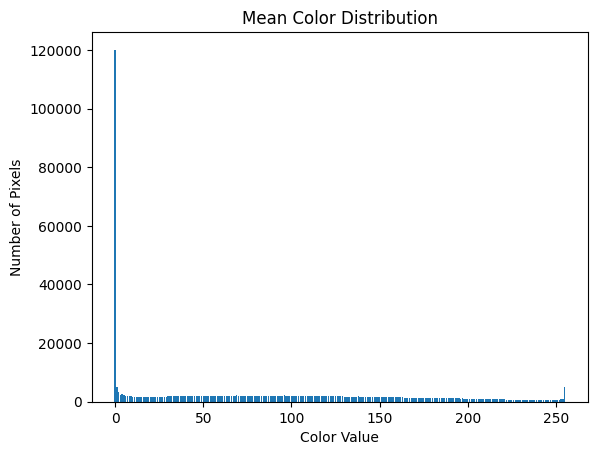

In [45]:
# Calculate the mean color distribution across all images
mean_color_distribution = np.mean(color_distributions, axis=0)

# Plot a bar chart of the mean color distribution
plt.bar(np.arange(256), mean_color_distribution)
plt.title("Mean Color Distribution")
plt.xlabel("Color Value")
plt.ylabel("Number of Pixels")
plt.show()